# Template refinement: multi-Otsu chromatin selection on hematoxylin

Given one click on a mitotic figure, this finds the figure's condensed chromatin around the click
and returns the template's size and centre: the chromatin's bounding box plus a 2 px margin,
centred on that bounding box. It works on the `hematoxylin_od` channel only.

**Method** (`refine_template_box`):
1. Read the 51 px window centred on the click.
2. Split it into 3 intensity classes with multi-Otsu (`skimage.filters.threshold_multiotsu`) and
   keep the top class -- the darkest hematoxylin, i.e. condensed chromatin (the other two classes
   are roughly background and ordinary nuclei).
3. Dilate that mask by 1 px (3x3 cross), so chromatin pieces 1-2 px apart join and each piece
   gets back a pixel of edge. Label the connected pieces (4-connectivity).
4. Ignore specks: pieces smaller than 1.0 um^2.
5. Select the figure:
   - **base case** -- the click lies on a piece whose bounding box is at least 5 um on its longer
     side: take that piece alone;
   - **fallback** -- otherwise (the click is on background, on a speck, or on a small piece):
     take every piece whose **centre** lies within 3.75 um of the click. This covers anaphase and
     telophase clicks, which land in the gap between two chromatin groups, and figures that break
     into several pieces.
6. Refuse if the selection covers less than 3.0 um^2, or more than 85% of the window.
7. Box: a square centred on the **selection's bounding box**, with side = the bounding box's
   longer side (rounded up to odd) + a **2 px** margin on each side. Every selected pixel sits
   at least 2 px inside the edge. That is the template's size and centre.

The window and the margin are in pixels. Every other size and distance is in micrometres, converted
per ROI with that ROI's own um/px.

| parameter | value |
|---|---|
| window | 51 px |
| classes | 3, keep the top one |
| dilation | 1 px, 3x3 cross |
| speck floor | 1.0 um^2 |
| base-case size | 5.0 um |
| fallback radius | 3.75 um, to piece centres |
| selection area | >= 3.0 um^2, <= 85% of the window |
| margin | 2 px on every side (0.45-0.51 um on these ROIs, at 0.2263-0.2533 um/px) |

**Known limits:**
- The 3.75 um radius was fitted on these 24 clicks. On `300.tiff`/14575 and `013.tiff`/243 a
  piece that belongs to the figure sits less than 0.1 um inside it.
- On `245.tiff`/6243 the box takes in a small piece of a neighbouring nucleus.
- This checks geometry only; it has not been run through precision@K.

In [1]:
import os
import sys

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.color import label2rgb
from skimage.filters import threshold_multiotsu
from skimage.measure import label, regionprops

sys.path.insert(0, '../..')
from midog_utils import channels as ch
from midog_utils import dataset as ds
from midog_utils import seed_selection as ss
from midog_utils import template_match as tm

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)

IMAGES_DIR = '../../images/extra_valid'
DB_PATH = '../../databases/MIDOG++.json'

WINDOW = tm.BASE_SIZE                                            # 51 px window around the click
CLASSES = 3                                                      # multi-Otsu classes; the top one is kept
DILATE_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))  # 3x3 cross
DILATE_ITERATIONS = 1                                            # 1 px
MIN_PIECE_UM2 = 1.0                                              # speck floor
MIN_BASE_UM = 5.0                                                # base case: the click's piece bbox, longer side
CLICK_RADIUS_UM = 3.75                                           # fallback: piece centre within this of the click
MIN_AREA_UM2 = 3.0                                               # selection must cover at least this
MAX_AREA_FRAC = 0.85                                             # ... and at most this fraction of the window
PAD_PX = 2                                                       # margin kept around the selection on every side

CONTEXT_WINDOW = 91                                              # display-only crop around the click
OUT_PREFIX = 'multiotsurefine14'

## The method

In [2]:
def refine_template_box(hem_img, cx, cy, mpp):
    """
        Find the mitotic figure's chromatin around a click and return the template box.
        hem_img (np.ndarray): the full-ROI hematoxylin_od channel.
        cx, cy (float): click position in ROI pixel coordinates.
        mpp (float): this ROI's microns per pixel.
        Returns dict: accepted (bool), reason (str), base_size (int, template side in px), center_xy (ROI x, y of the template centre, on the selection's bounding box), plus intermediates for plotting.
    """
    hem_patch = tm.read_padded_patch(hem_img, cx, cy, WINDOW)
    result = dict(accepted=False, reason='too close to the ROI border to read the window', base_size=None, center_xy=None,
                  hem_patch=hem_patch, thresholds=None, class_map=None, labels=None, pieces=[], mode=None,
                  selected=[], selection_mask=None, bbox=None, radius_px=CLICK_RADIUS_UM / mpp, pad_px=PAD_PX)
    if hem_patch is None:
        return result

    patch = hem_patch.astype(np.float64)
    py, px = patch.shape[0] // 2, patch.shape[1] // 2
    thresholds = threshold_multiotsu(patch, classes=CLASSES)
    top_class = cv2.dilate((patch > thresholds[-1]).astype(np.uint8), DILATE_KERNEL, iterations=DILATE_ITERATIONS) > 0
    labels = label(top_class, connectivity=1)
    result.update(thresholds=[float(t) for t in thresholds], class_map=np.digitize(patch, thresholds), labels=labels)

    pieces = []
    for r in regionprops(labels):
        ys, xs = r.coords[:, 0], r.coords[:, 1]
        y0, x0, y1, x1 = r.bbox
        pieces.append(dict(label=int(r.label), area_um2=r.area * mpp ** 2, centre_um=float(np.hypot(ys.mean() - py, xs.mean() - px)) * mpp,
                           bbox_um=max(y1 - y0, x1 - x0) * mpp, centre_yx=(float(ys.mean()), float(xs.mean())), speck=r.area * mpp ** 2 < MIN_PIECE_UM2))
    result['pieces'] = pieces
    by_label = {p['label']: p for p in pieces}

    clicked = int(labels[py, px])
    if clicked and not by_label[clicked]['speck'] and by_label[clicked]['bbox_um'] >= MIN_BASE_UM:
        result['mode'] = 'base'
        selected = [clicked]
    else:
        result['mode'] = 'fallback'
        selected = [p['label'] for p in pieces if not p['speck'] and p['centre_um'] <= CLICK_RADIUS_UM]
    for p in pieces:
        p['selected'] = p['label'] in selected
    result['selected'] = selected
    if not selected:
        result['reason'] = f'no piece centre within {CLICK_RADIUS_UM}um of the click'
        return result

    mask = np.isin(labels, selected)
    result['selection_mask'] = mask
    if mask.sum() * mpp ** 2 < MIN_AREA_UM2:
        result['reason'] = f'selection {mask.sum() * mpp ** 2:.2f}um^2 < {MIN_AREA_UM2}um^2'
        return result
    if mask.sum() > MAX_AREA_FRAC * patch.size:
        result['reason'] = f'selection covers more than {MAX_AREA_FRAC:.0%} of the window'
        return result

    ys, xs = np.where(mask)
    y0, y1, x0, x1 = int(ys.min()), int(ys.max()) + 1, int(xs.min()), int(xs.max()) + 1
    half = WINDOW // 2
    ix, iy = int(round(cx)), int(round(cy))
    result.update(accepted=True, reason='accepted', bbox=(y0, y1, x0, x1), base_size=ss._odd(max(y1 - y0, x1 - x0), minimum=5) + 2 * result['pad_px'],
                  center_xy=(ix - half + (x0 + x1 - 1) / 2.0, iy - half + (y0 + y1 - 1) / 2.0))
    return result


print('refine_template_box defined')

refine_template_box defined


In [3]:
def context_crop(rgb, cx, cy):
    """
        The CONTEXT_WINDOW-sized RGB crop centred on a point, white where it runs past the ROI edge.
        rgb (np.ndarray): the full-ROI RGB image.
        cx, cy (float): centre in ROI pixel coordinates.
        Returns np.ndarray: the crop, CONTEXT_WINDOW x CONTEXT_WINDOW x 3.
    """
    half = CONTEXT_WINDOW // 2
    ix, iy = int(round(cx)), int(round(cy))
    out = np.full((CONTEXT_WINDOW, CONTEXT_WINDOW, 3), 255, dtype=rgb.dtype)
    y0, y1, x0, x1 = max(0, iy - half), min(rgb.shape[0], iy + half + 1), max(0, ix - half), min(rgb.shape[1], ix + half + 1)
    out[y0 - (iy - half):y1 - (iy - half), x0 - (ix - half):x1 - (ix - half)] = rgb[y0:y1, x0:x1]
    return out


def plot_refinement(axes, res, rgb, cx, cy):
    """
        Draw one click: hem window, 3-class map, pieces, box in context, final template.
        axes (np.ndarray): five matplotlib axes.
        res (dict): refine_template_box's result.
        rgb (np.ndarray): the full-ROI RGB image.
        cx, cy (float): click position in ROI pixel coordinates.
        Returns None: draws into axes.
    """
    ax_patch, ax_classes, ax_pieces, ax_context, ax_template = axes
    for a in axes:
        a.axis('off')
    if res['hem_patch'] is None:
        ax_patch.text(0.5, 0.5, res['reason'], ha='center', va='center', wrap=True)
        return

    c = WINDOW // 2
    ax_patch.imshow(res['hem_patch'], cmap='gray')
    ax_patch.plot(c, c, marker='+', color='red', ms=13, mew=2)
    ax_patch.add_patch(plt.Circle((c, c), res['radius_px'], fill=False, edgecolor='yellow', linestyle='--', linewidth=1.5))
    ax_patch.set_title('hematoxylin_od window\nclick + fallback radius', fontsize=9)

    ax_classes.imshow(res['class_map'], cmap='gray', vmin=0, vmax=CLASSES - 1)
    ax_classes.plot(c, c, marker='+', color='red', ms=13, mew=2)
    ax_classes.set_title(f'{CLASSES}-class multi-Otsu (white = kept)\ncuts ' + ', '.join(f'{t:.3f}' for t in res['thresholds']), fontsize=9)

    ax_pieces.imshow(label2rgb(res['labels'], bg_label=0))
    ax_pieces.plot(c, c, marker='+', color='white', ms=13, mew=2)
    ax_pieces.add_patch(plt.Circle((c, c), res['radius_px'], fill=False, edgecolor='yellow', linestyle='--', linewidth=1.5))
    for p in res['pieces']:
        if p['speck'] or p['centre_um'] > 6.0:
            continue
        colour, width = ('lime', 2) if p['selected'] else ('red', 1)
        ax_pieces.contour(res['labels'] == p['label'], levels=[0.5], colors=colour, linewidths=width)
        ax_pieces.plot(p['centre_yx'][1], p['centre_yx'][0], marker='o', color=colour, ms=4)
    verdict = 'accepted' if res['accepted'] else f"REFUSED: {res['reason']}"
    ax_pieces.set_title(f"pieces after 1px dilation, {res['mode']}\nlime = selected, red = not selected -- {verdict}", fontsize=8)

    half_ctx = CONTEXT_WINDOW // 2
    ix, iy = int(round(cx)), int(round(cy))
    ax_context.imshow(context_crop(rgb, cx, cy))
    ax_context.plot(half_ctx, half_ctx, marker='x', color='red', ms=11, mew=2)
    if res['accepted']:
        bs = res['base_size']
        icx, icy = int(round(res['center_xy'][0])), int(round(res['center_xy'][1]))
        bh = (bs - 1) // 2
        ax_context.add_patch(plt.Rectangle((icx - bh - (ix - half_ctx) - 0.5, icy - bh - (iy - half_ctx) - 0.5), bs, bs, fill=False, edgecolor='cyan', linewidth=2))
        ax_context.plot(icx - (ix - half_ctx), icy - (iy - half_ctx), marker='o', color='lime', ms=6)
        ax_context.set_title(f'box in context ({CONTEXT_WINDOW}px crop)\nred x = click, lime = template centre', fontsize=9)
        tpl = tm.read_padded_patch(rgb, res['center_xy'][0], res['center_xy'][1], bs)
        if tpl is not None:
            ax_template.imshow(tpl)
        ax_template.set_title(f'template {bs}x{bs}px', fontsize=9)
    else:
        ax_context.set_title('refused', fontsize=9, color='firebrick')


print('context_crop / plot_refinement defined')

context_crop / plot_refinement defined


## The 24 clicks

24 mitotic annotations from 14 ROIs in `images/extra_valid/`, covering all 7 MIDOG++ domains.
Each is looked up by its annotation id and must be a mitotic annotation.

In [4]:
CLICK_IDS = [
    ('300.tiff', 14499), ('300.tiff', 14575), ('300.tiff', 14581), ('301.tiff', 14969),
    ('201.tiff', 4457), ('201.tiff', 4469), ('233.tiff', 5761),
    ('245.tiff', 6243), ('245.tiff', 6274), ('245.tiff', 6317), ('246.tiff', 6548),
    ('459.tiff', 22441), ('459.tiff', 22446), ('460.tiff', 22577),
    ('013.tiff', 243), ('013.tiff', 249), ('013.tiff', 254), ('094.tiff', 2512),
    ('529.tiff', 24918), ('529.tiff', 24937), ('548.tiff', 25804),
    ('402.tiff', 20254), ('402.tiff', 20258), ('403.tiff', 20356),
]

images, annotations = ds.load_annotations(DB_PATH)
domain_of = images.set_index('file_name')['tumor_type']

ROIS = {}
for fn in sorted({fn for fn, _ in CLICK_IDS}):
    rgb = ds.load_roi(f'{IMAGES_DIR}/{fn}')
    ROIS[fn] = dict(rgb=rgb, hem=ch.to_channel(rgb, 'hematoxylin_od'), mpp=ds.roi_mpp(f'{IMAGES_DIR}/{fn}'))

CLICKS = []
for fn, ann_id in CLICK_IDS:
    row = ds.image_annotations(annotations, fn)
    row = row[row['ann_id'] == ann_id]
    assert len(row) == 1 and int(row.iloc[0]['category_id']) == ds.MITOTIC, f'{fn}/{ann_id}: expected one mitotic annotation'
    CLICKS.append(dict(file_name=fn, ann_id=ann_id, cx=float(row.iloc[0]['cx']), cy=float(row.iloc[0]['cy']), domain=domain_of[fn]))

print(f'{len(CLICKS)} clicks from {len(ROIS)} ROIs, {len({c["domain"] for c in CLICKS})} domains')

24 clicks from 14 ROIs, 7 domains


## Run

`EXPECTED_BASE_SIZE` holds the template sizes this method produced when it was adopted
(2026-09-29). A mismatch means the method or its inputs changed. Switching the margin from 0.5 um
to a fixed 2 px (2026-09-30) left all 24 unchanged, because 0.5 um rounded to 2 px on every ROI.
The run also checks the margin: every selected pixel must sit at least 2 px inside its box.

In [5]:
EXPECTED_BASE_SIZE = {
    ('300.tiff', 14499): 29, ('300.tiff', 14575): 33, ('300.tiff', 14581): 35, ('301.tiff', 14969): 37,
    ('201.tiff', 4457): 33, ('201.tiff', 4469): 33, ('233.tiff', 5761): 29,
    ('245.tiff', 6243): 33, ('245.tiff', 6274): 39, ('245.tiff', 6317): 25, ('246.tiff', 6548): 31,
    ('459.tiff', 22441): 35, ('459.tiff', 22446): 41, ('460.tiff', 22577): 41,
    ('013.tiff', 243): 45, ('013.tiff', 249): 41, ('013.tiff', 254): 35, ('094.tiff', 2512): 27,
    ('529.tiff', 24918): 31, ('529.tiff', 24937): 33, ('548.tiff', 25804): 33,
    ('402.tiff', 20254): 31, ('402.tiff', 20258): 37, ('403.tiff', 20356): 35,
}

RESULTS = {}
for c in CLICKS:
    roi = ROIS[c['file_name']]
    RESULTS[(c['file_name'], c['ann_id'])] = refine_template_box(roi['hem'], c['cx'], c['cy'], roi['mpp'])

mismatches = {k: (r['base_size'], EXPECTED_BASE_SIZE[k]) for k, r in RESULTS.items() if r['base_size'] != EXPECTED_BASE_SIZE[k]}
print(f"accepted {sum(r['accepted'] for r in RESULTS.values())}/{len(RESULTS)}; template sizes matching EXPECTED_BASE_SIZE: {len(RESULTS) - len(mismatches)}/{len(RESULTS)}")
assert not mismatches, mismatches

margin_failures = []
for k, r in RESULTS.items():
    if r['accepted']:
        ys, xs = np.where(r['selection_mask'])
        c = next(c for c in CLICKS if (c['file_name'], c['ann_id']) == k)
        icx = int(round(r['center_xy'][0])) - (int(round(c['cx'])) - WINDOW // 2)
        icy = int(round(r['center_xy'][1])) - (int(round(c['cy'])) - WINDOW // 2)
        if max(np.abs(xs - icx).max(), np.abs(ys - icy).max()) > (r['base_size'] - 1) // 2 - r['pad_px']:
            margin_failures.append(k)
n_accepted = sum(r['accepted'] for r in RESULTS.values())
print(f'selected pixels at least {PAD_PX} px inside the box: {n_accepted - len(margin_failures)}/{n_accepted}')
assert not margin_failures, margin_failures

accepted 24/24; template sizes matching EXPECTED_BASE_SIZE: 24/24
selected pixels at least 2 px inside the box: 24/24


## All 24 boxes

Each panel is a 91 px crop around the click (red x), with the template box (cyan) and its centre (lime).

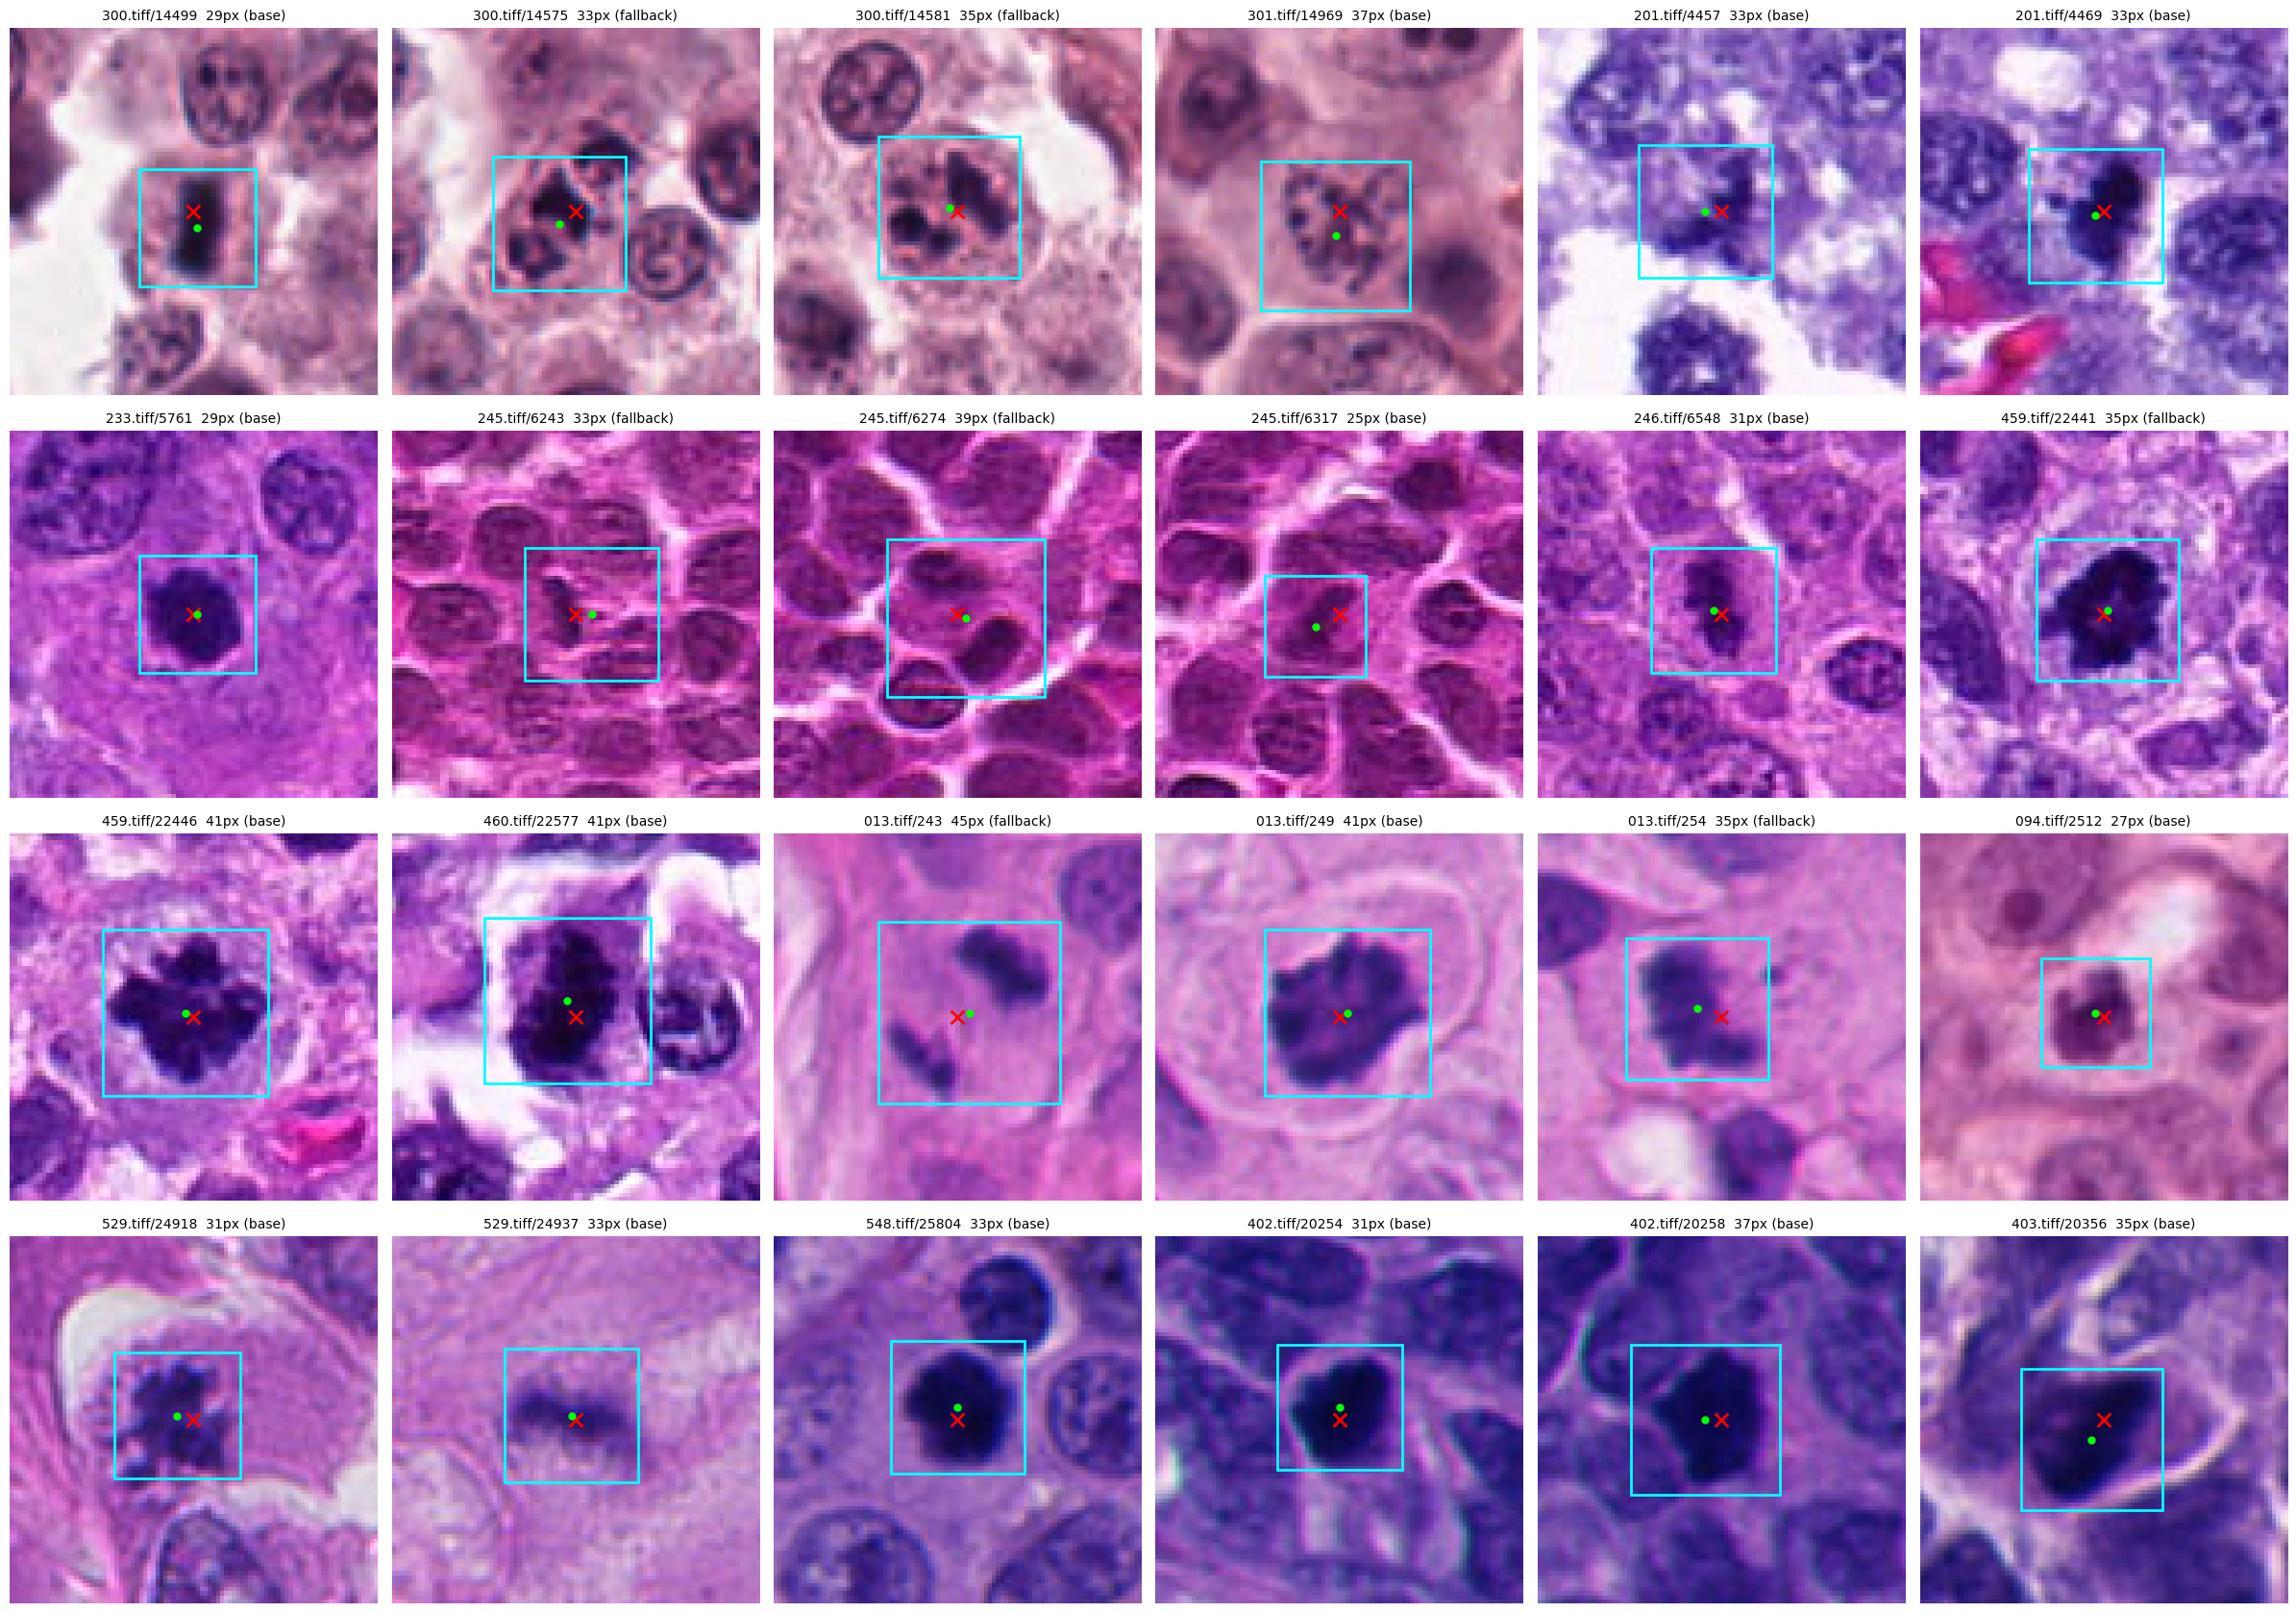

In [6]:
fig, axes = plt.subplots(4, 6, figsize=(24, 17))
half_ctx = CONTEXT_WINDOW // 2
for ax, c in zip(axes.ravel(), CLICKS):
    r = RESULTS[(c['file_name'], c['ann_id'])]
    rgb, ix, iy = ROIS[c['file_name']]['rgb'], int(round(c['cx'])), int(round(c['cy']))
    ax.imshow(context_crop(rgb, c['cx'], c['cy']))
    ax.plot(half_ctx, half_ctx, 'x', color='red', ms=10, mew=2)
    if r['accepted']:
        bs = r['base_size']
        icx, icy = int(round(r['center_xy'][0])), int(round(r['center_xy'][1]))
        bh = (bs - 1) // 2
        ax.add_patch(plt.Rectangle((icx - bh - (ix - half_ctx) - 0.5, icy - bh - (iy - half_ctx) - 0.5), bs, bs, fill=False, edgecolor='cyan', linewidth=2))
        ax.plot(icx - (ix - half_ctx), icy - (iy - half_ctx), 'o', color='lime', ms=5)
    ax.set_title(f"{c['file_name']}/{c['ann_id']}  {r['base_size']}px ({r['mode']})", fontsize=10)
    ax.axis('off')
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_overview.png', dpi=100, bbox_inches='tight')
plt.show()
plt.close(fig)

## Per-click detail

One row per click: the hematoxylin window with the fallback radius, the 3-class map, the pieces
after dilation (selected in lime with their centres; unselected non-speck pieces within 6 um in
red), the box in context, and the final template.

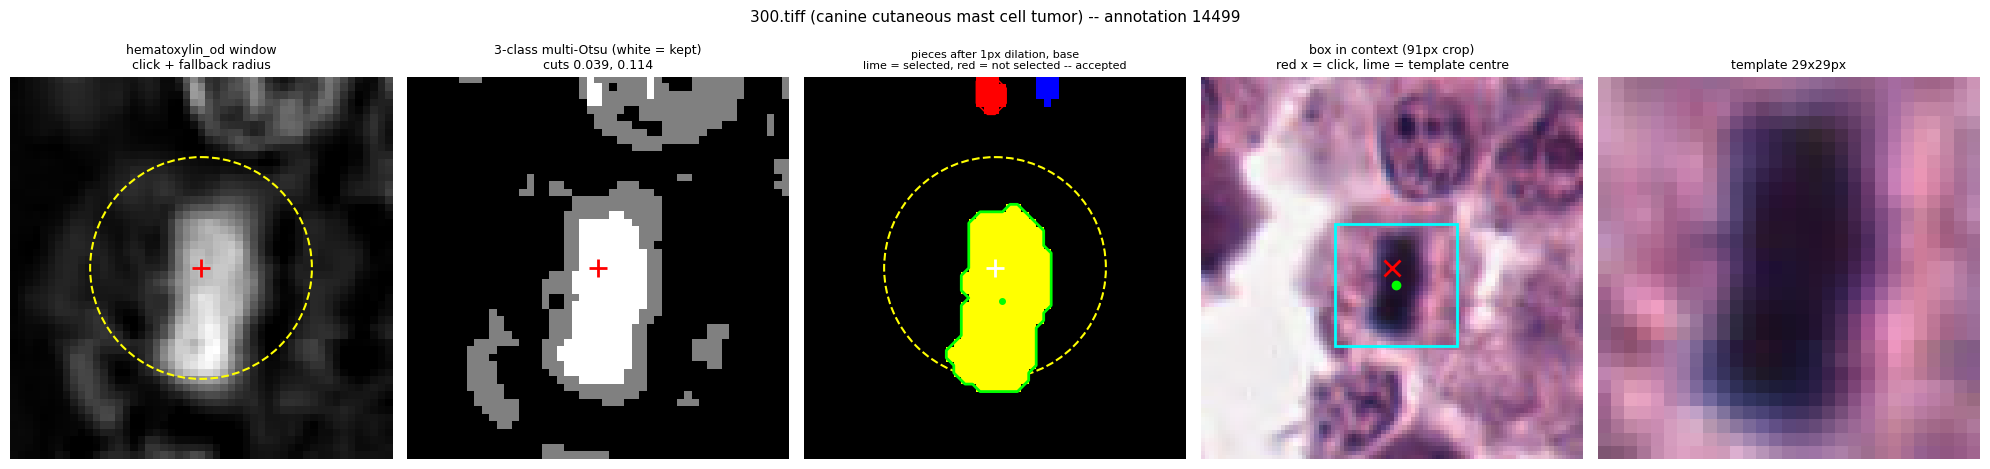

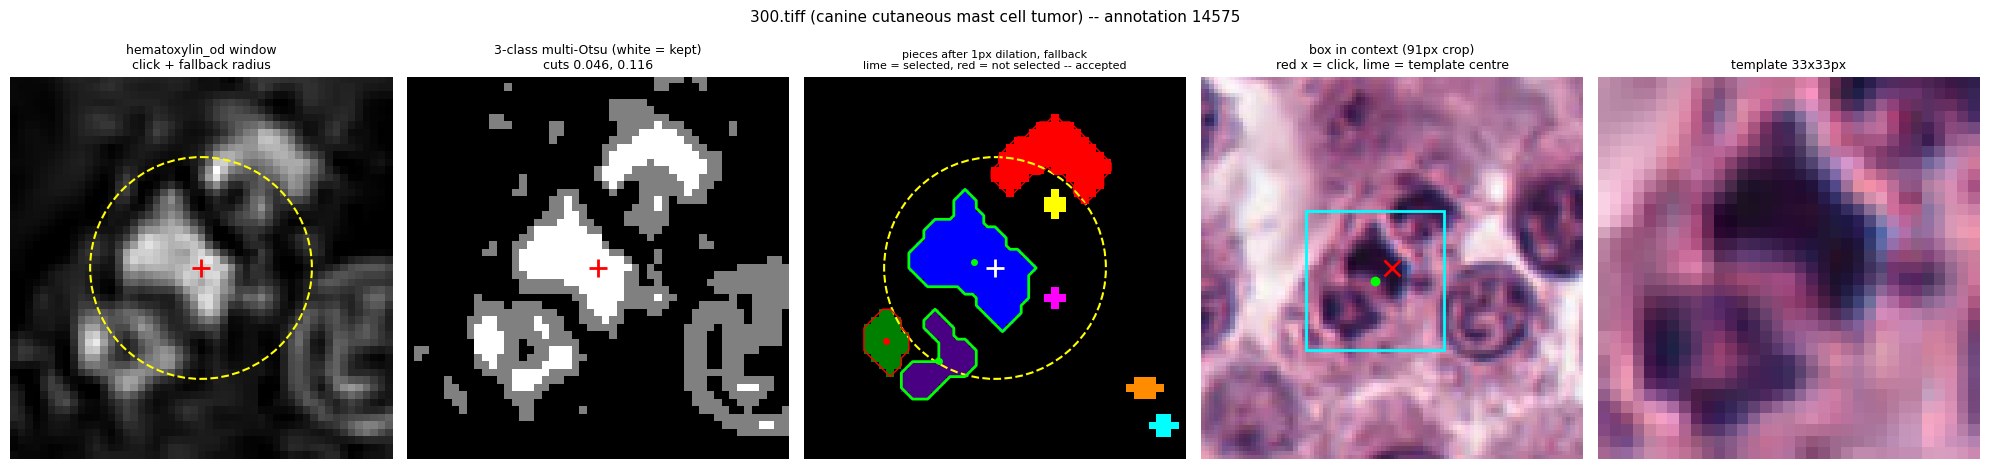

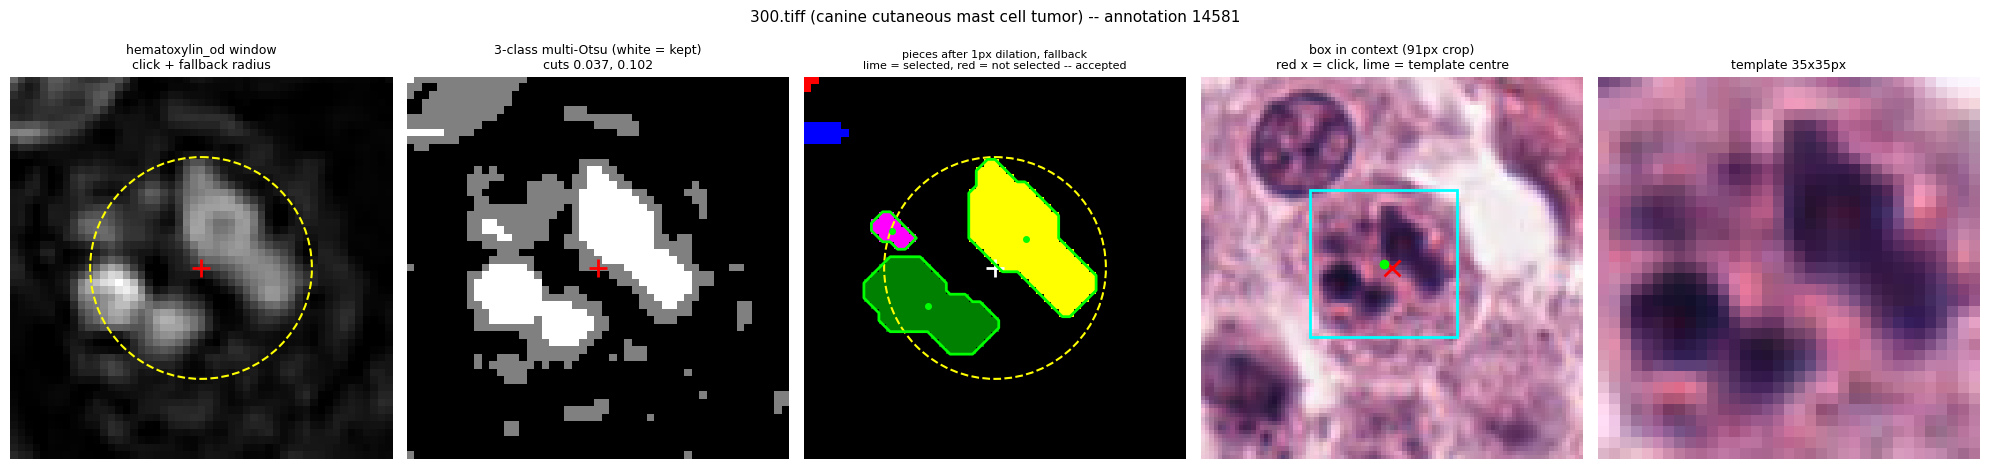

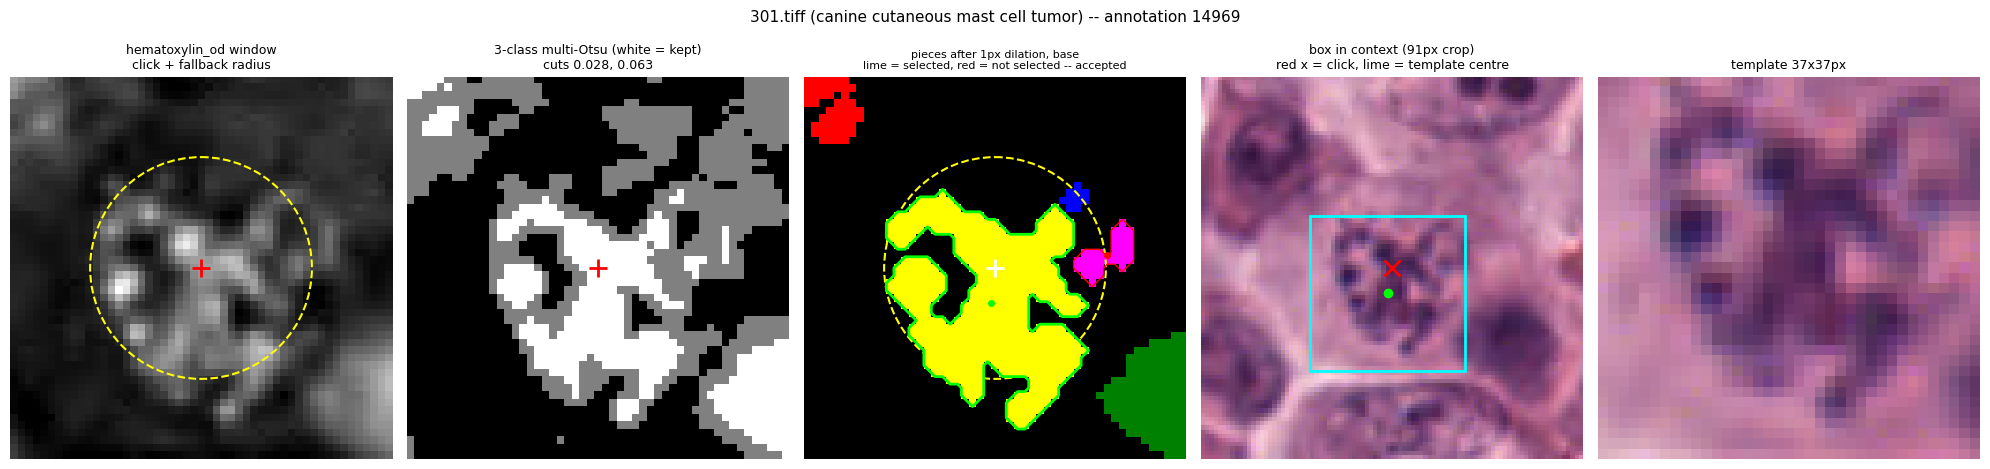

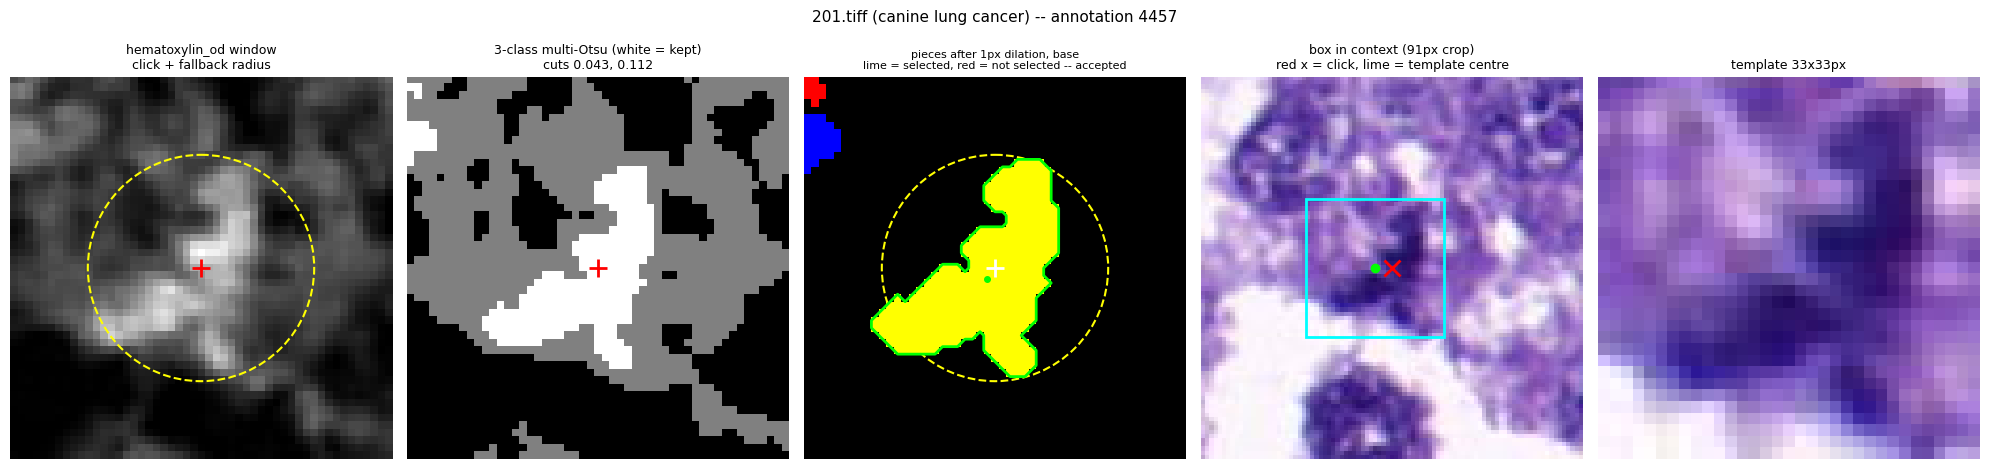

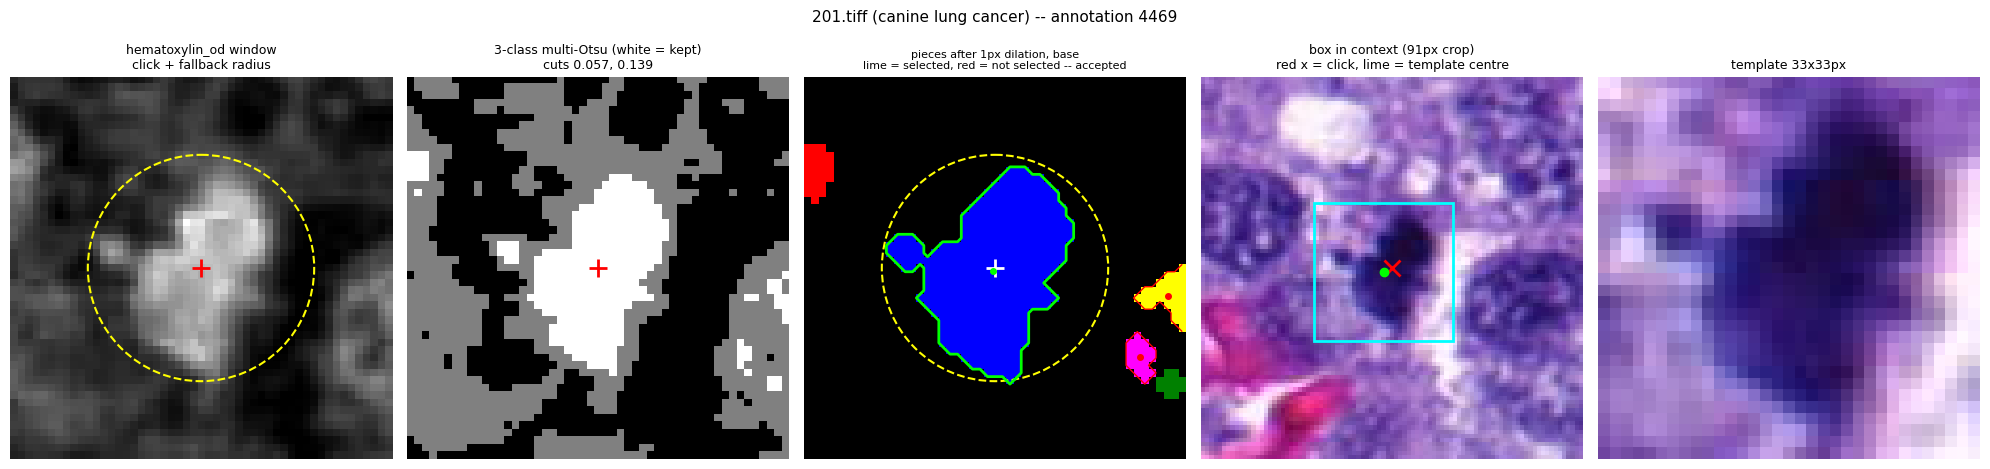

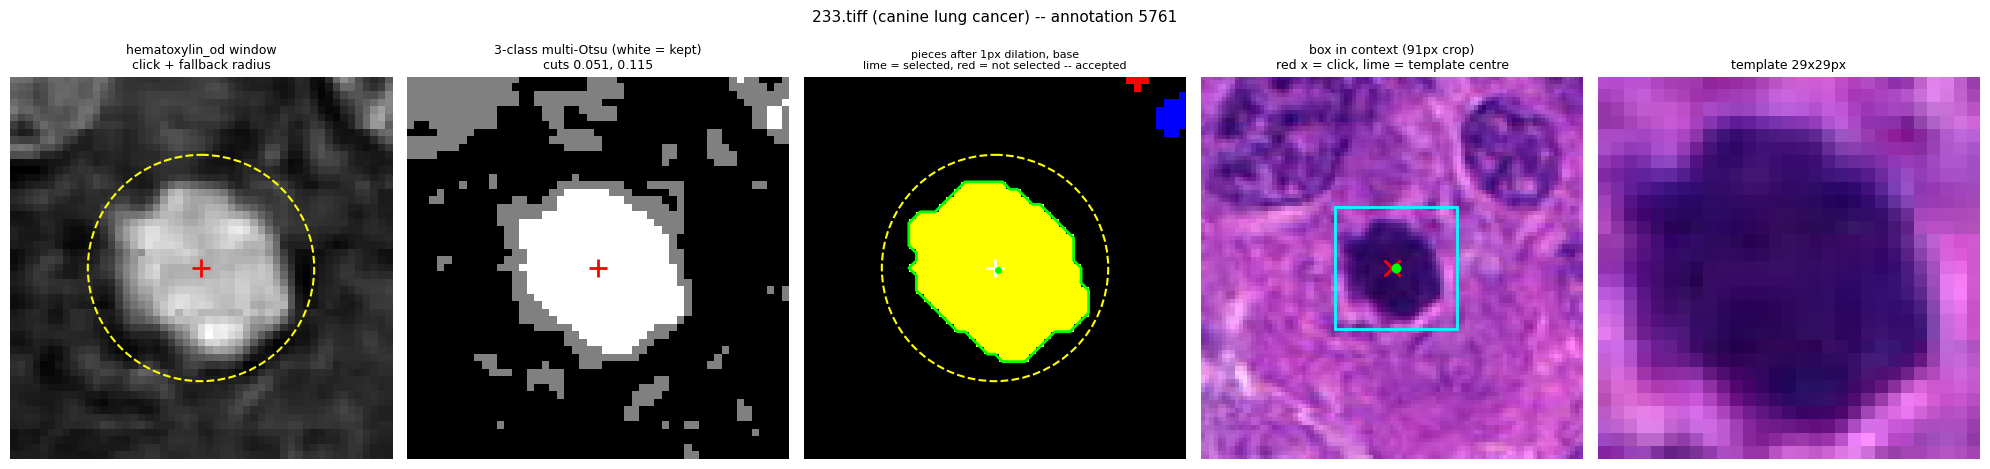

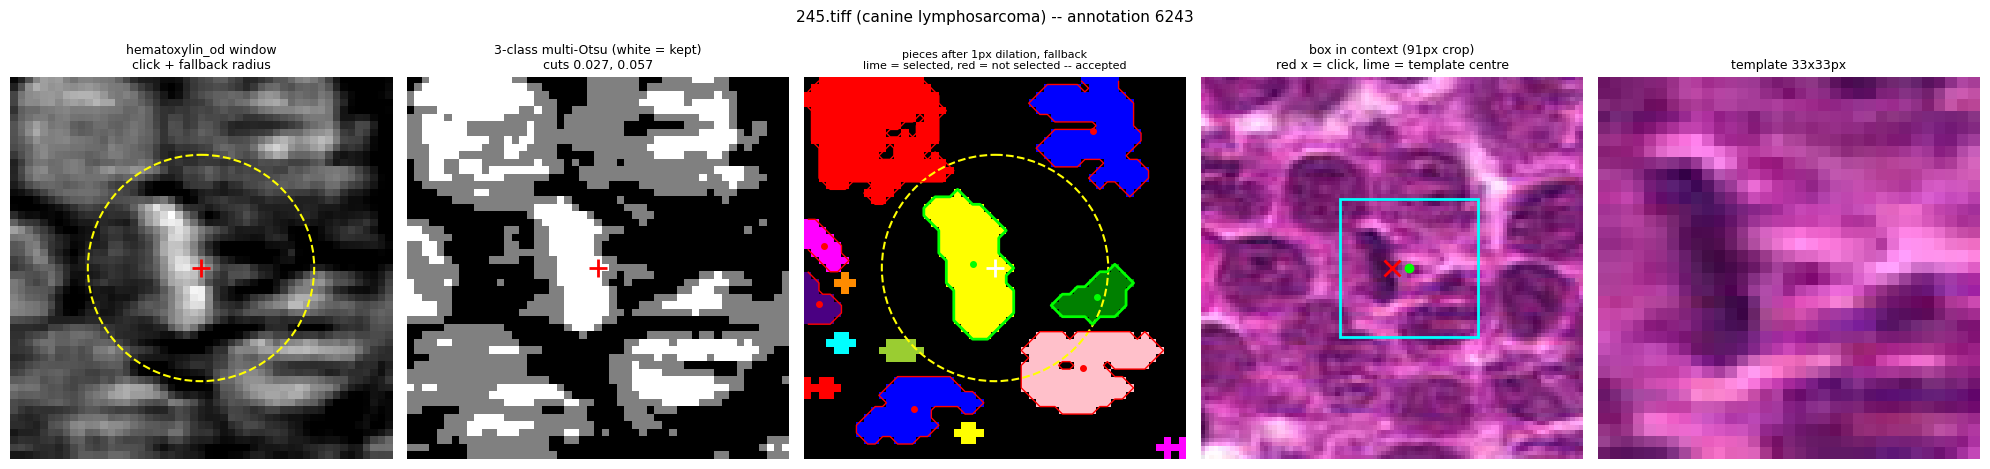

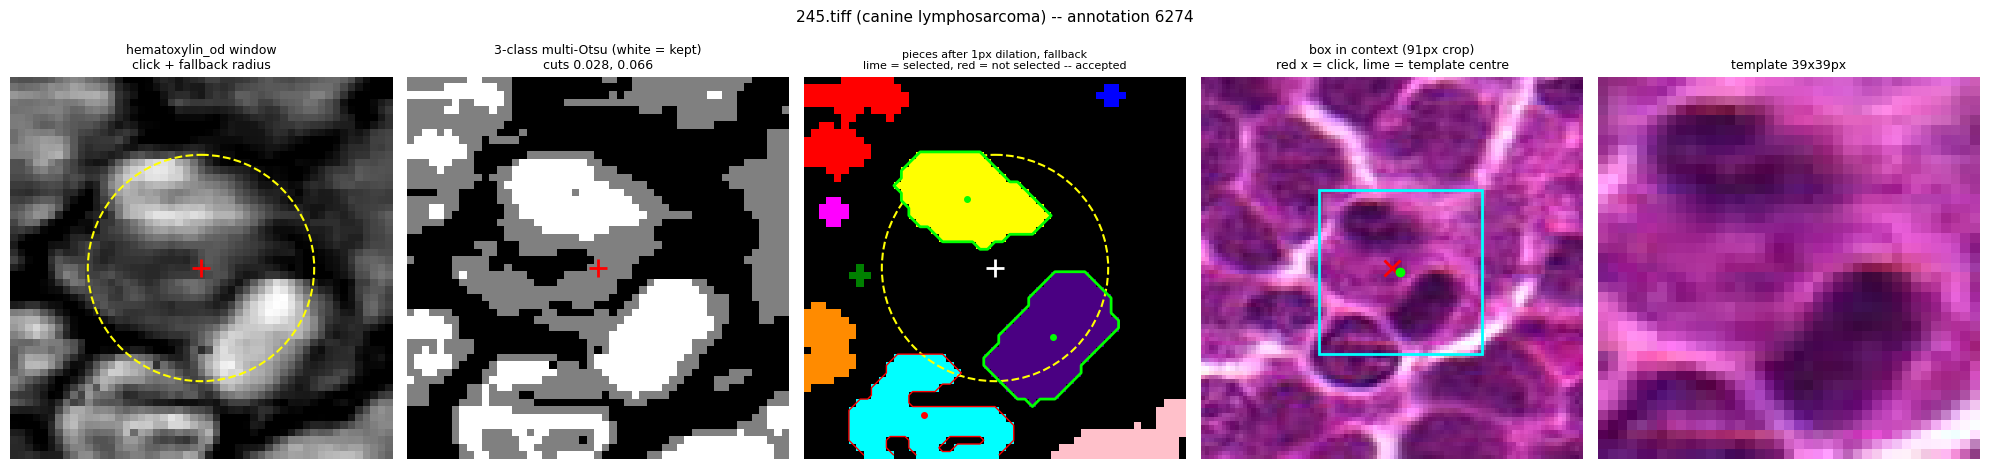

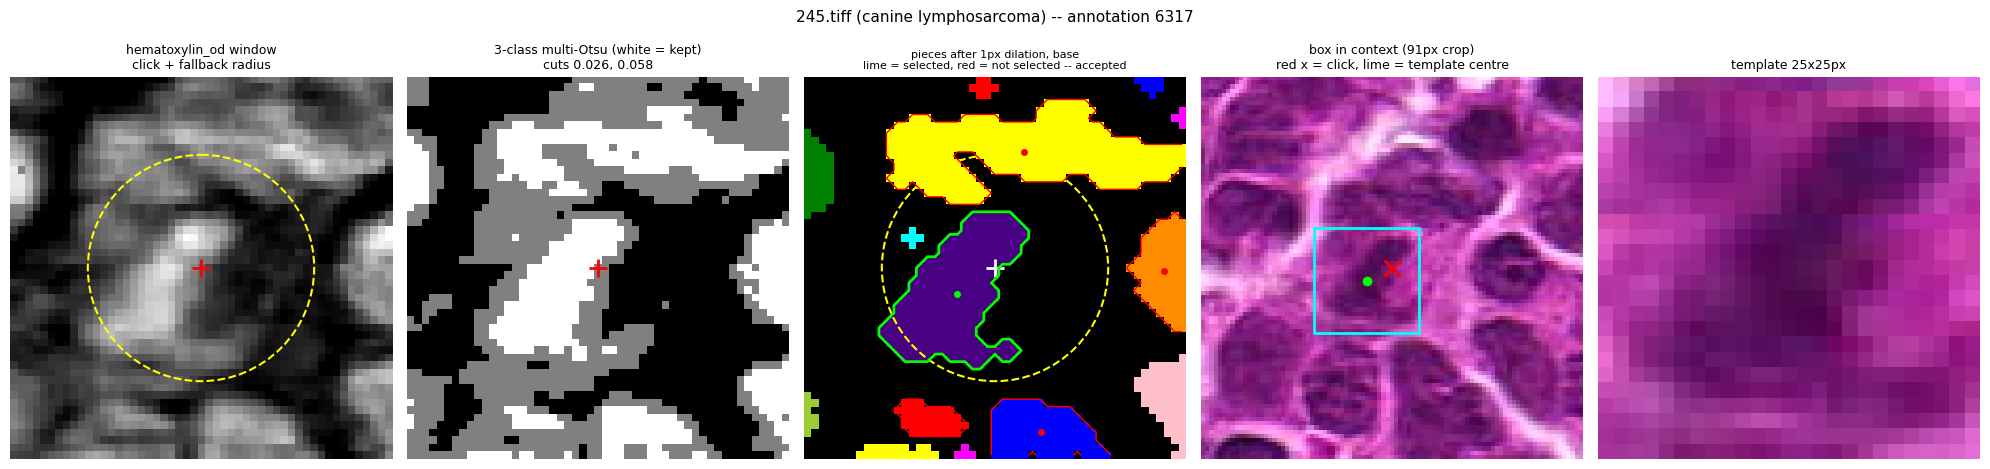

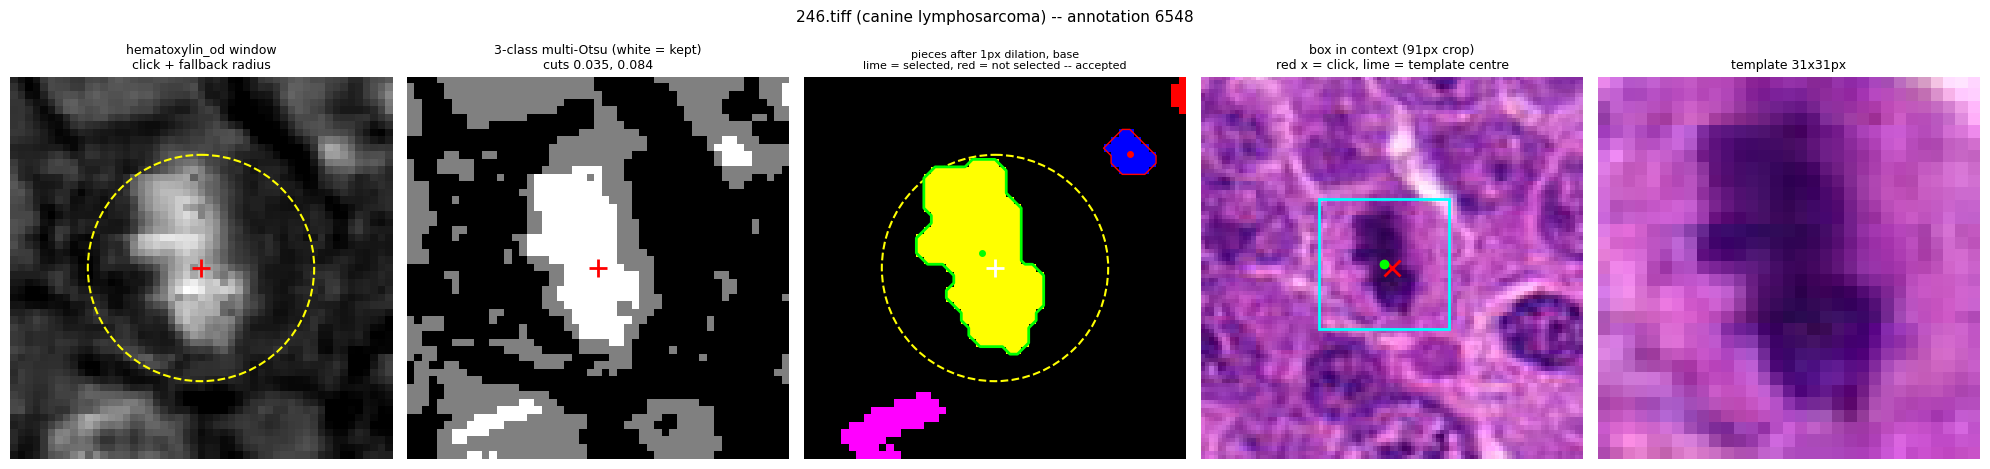

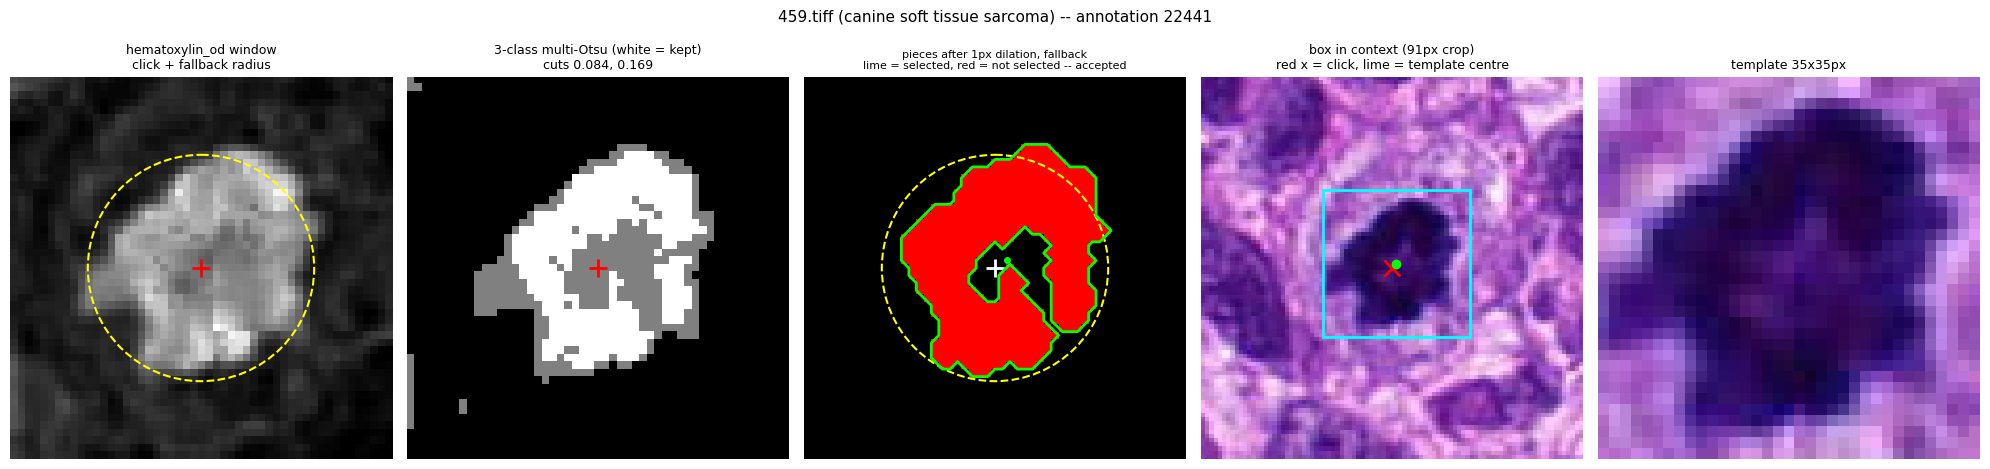

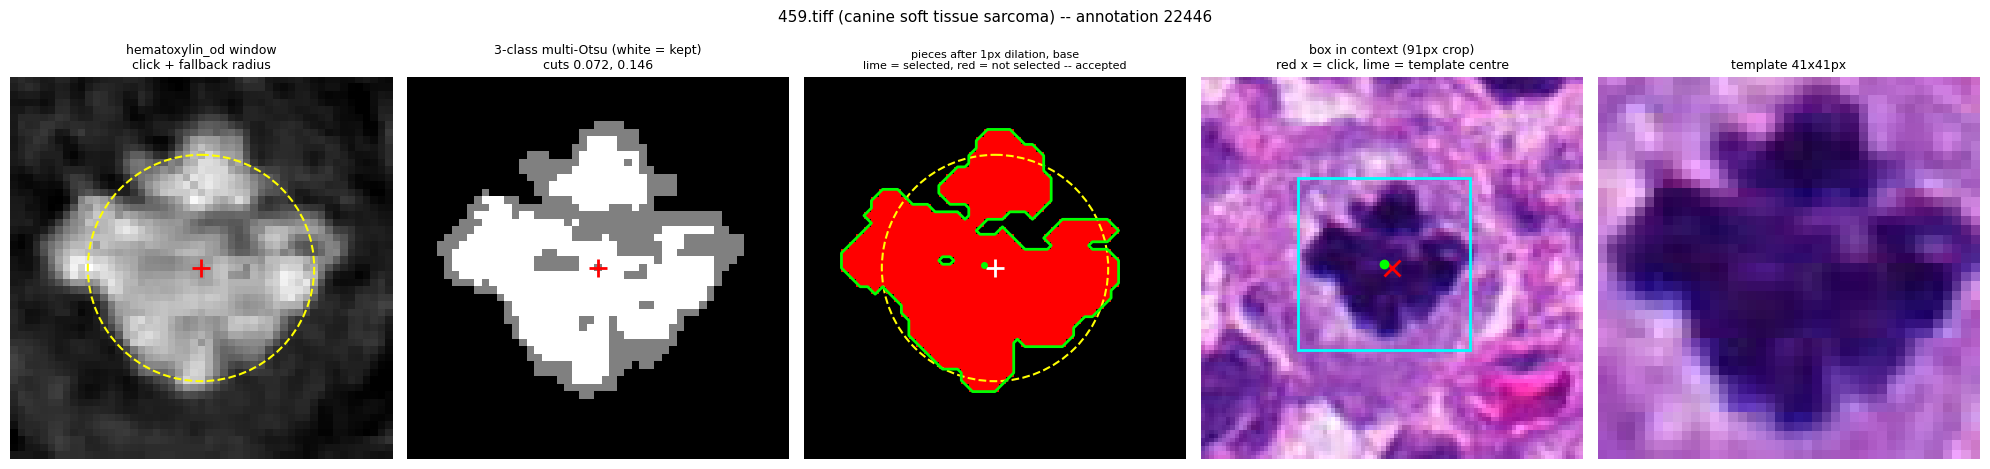

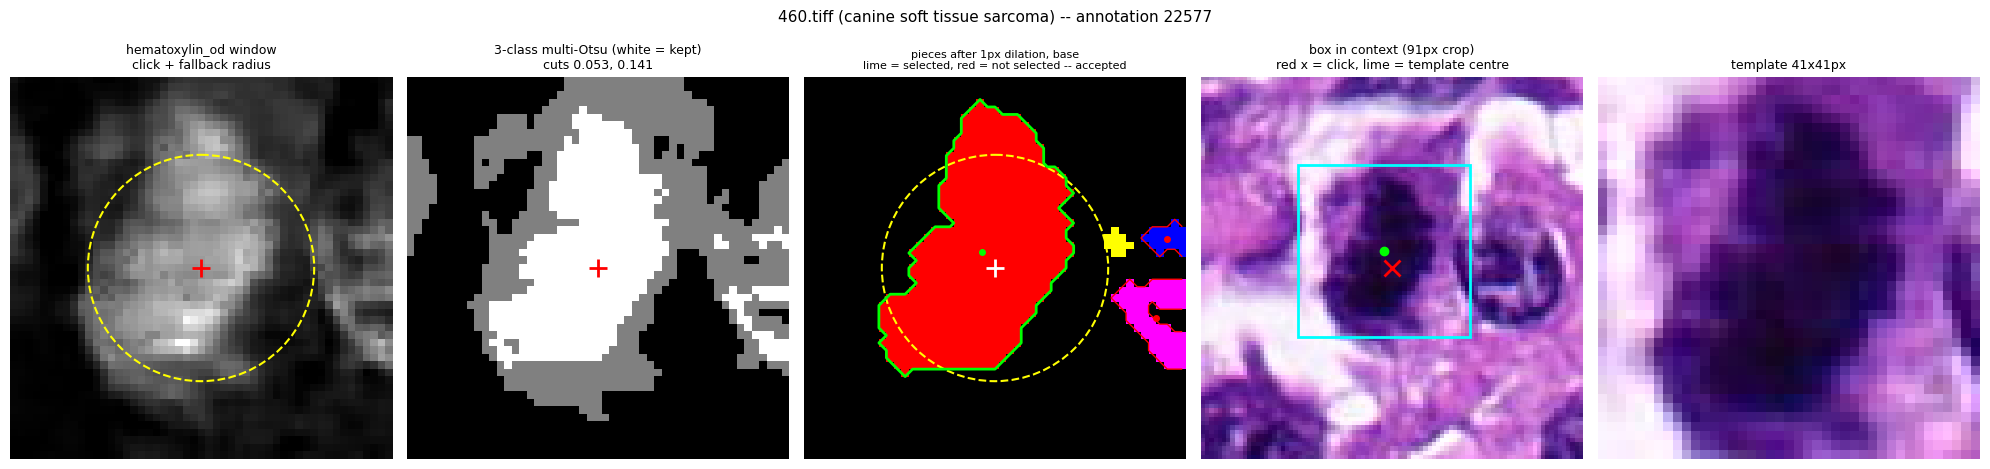

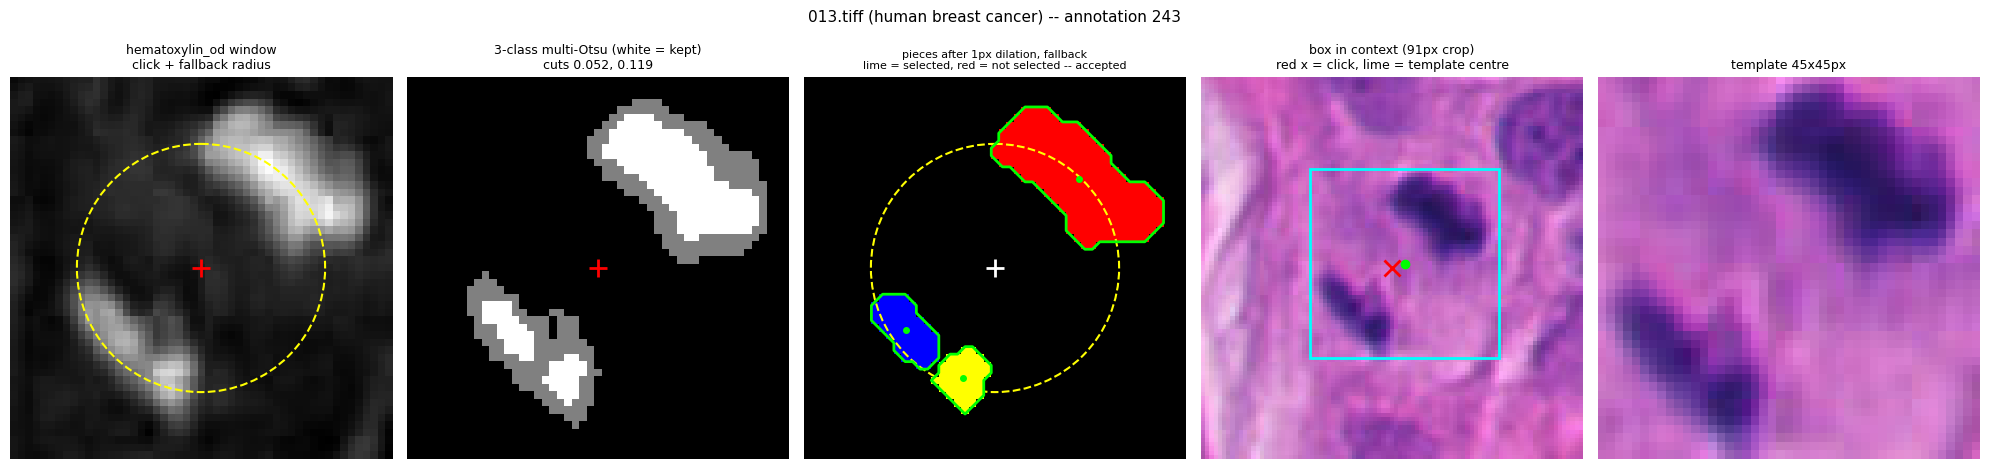

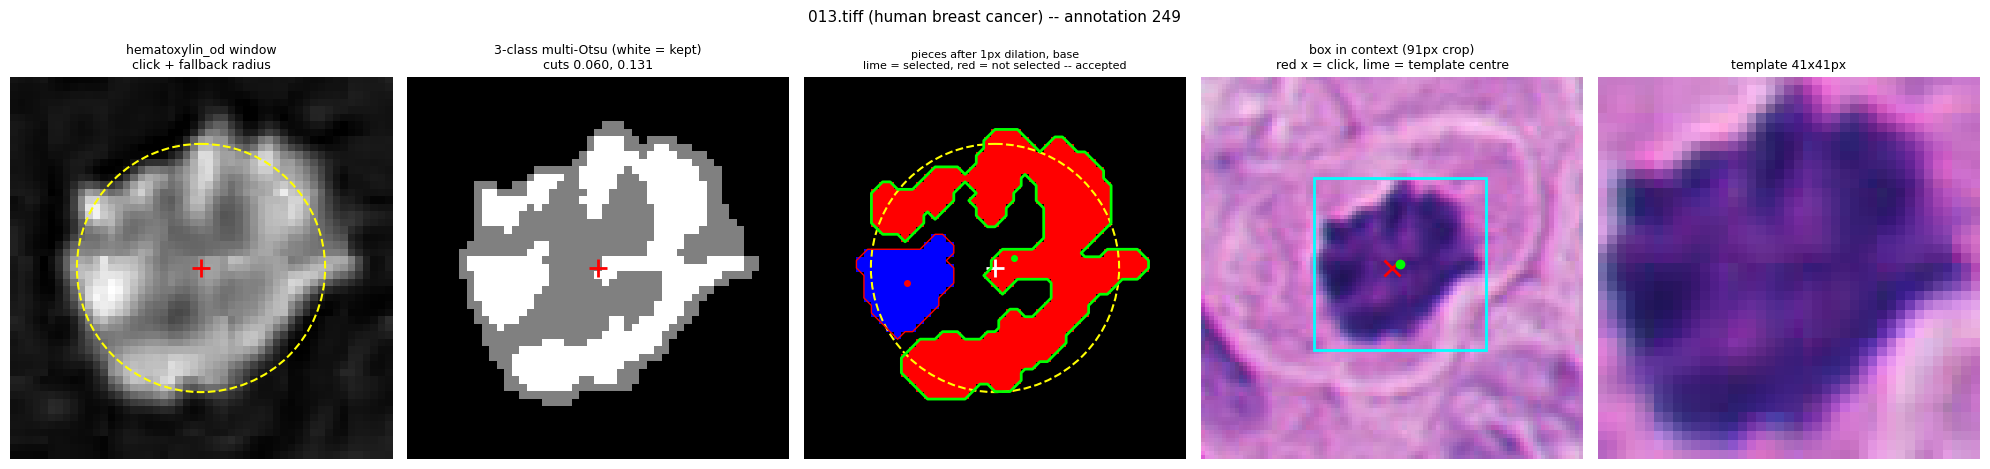

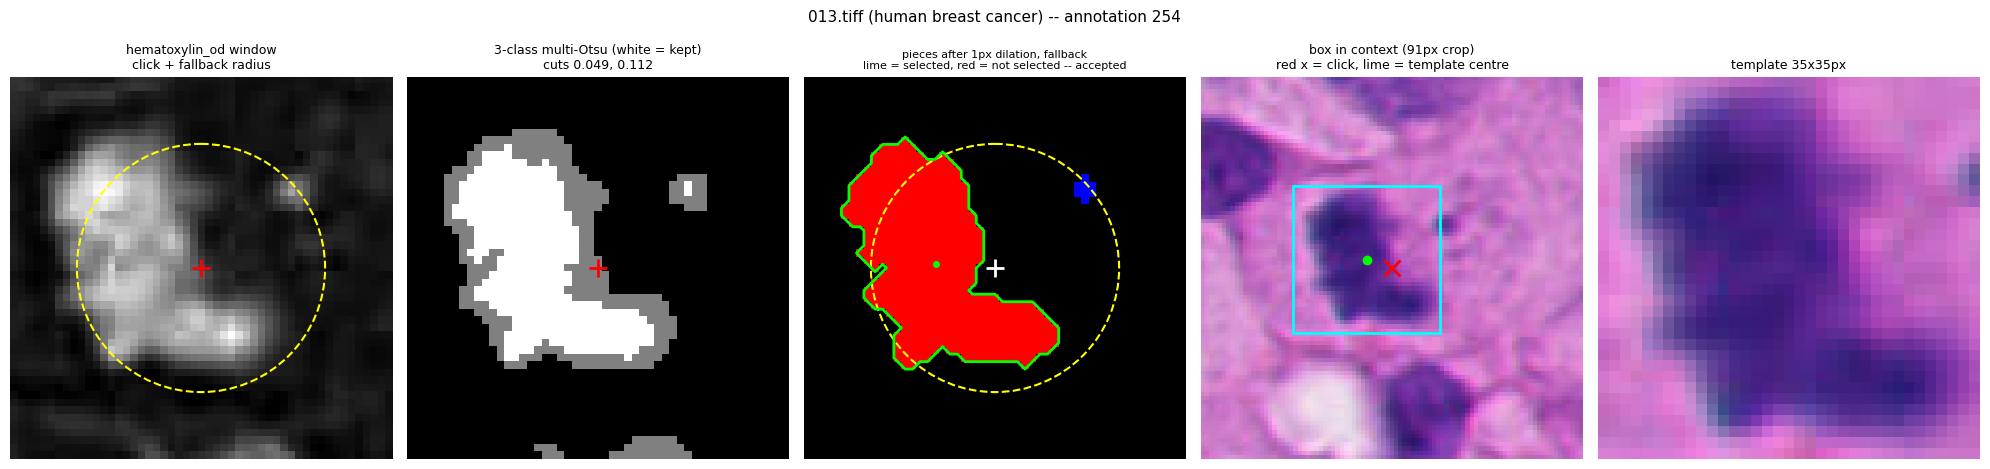

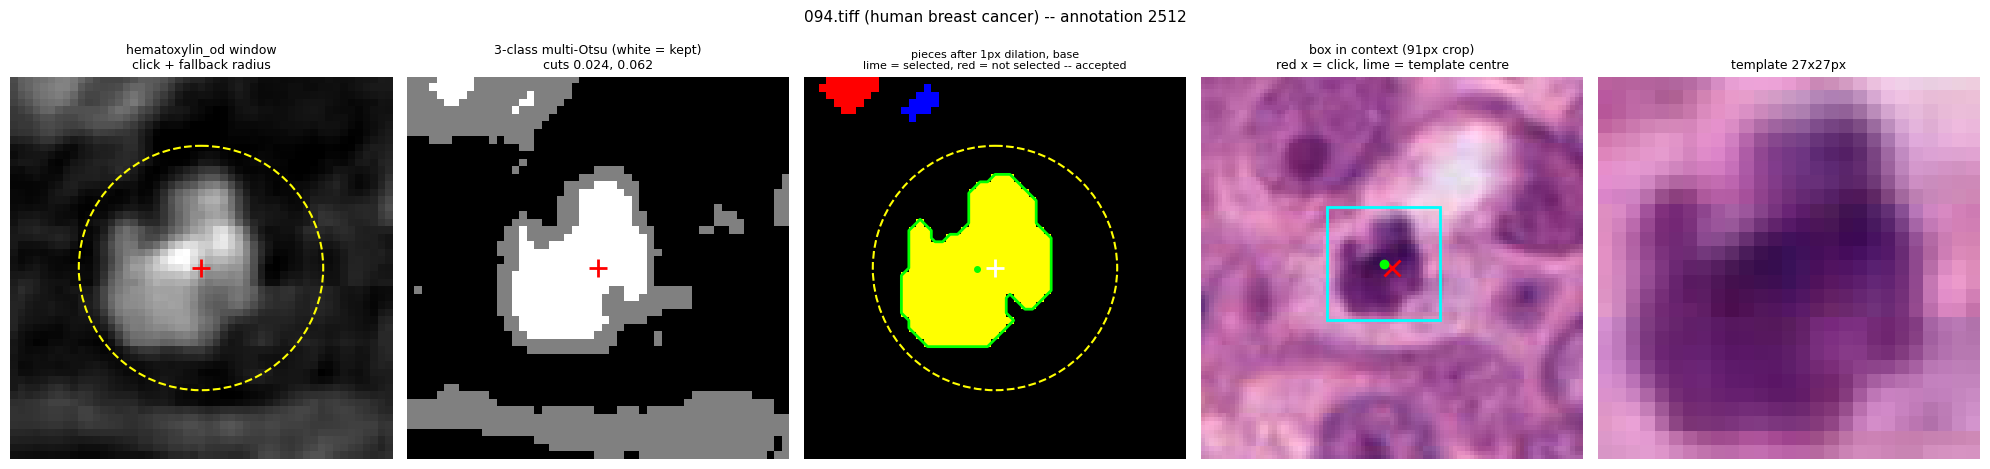

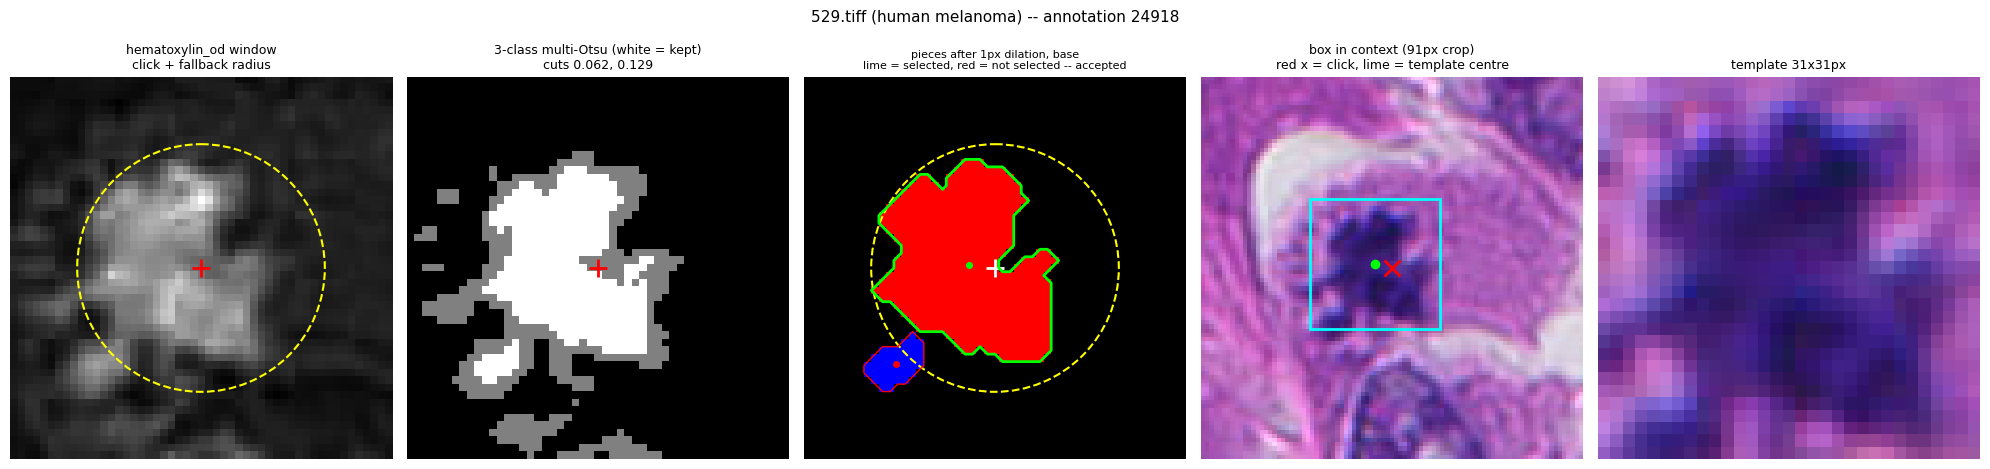

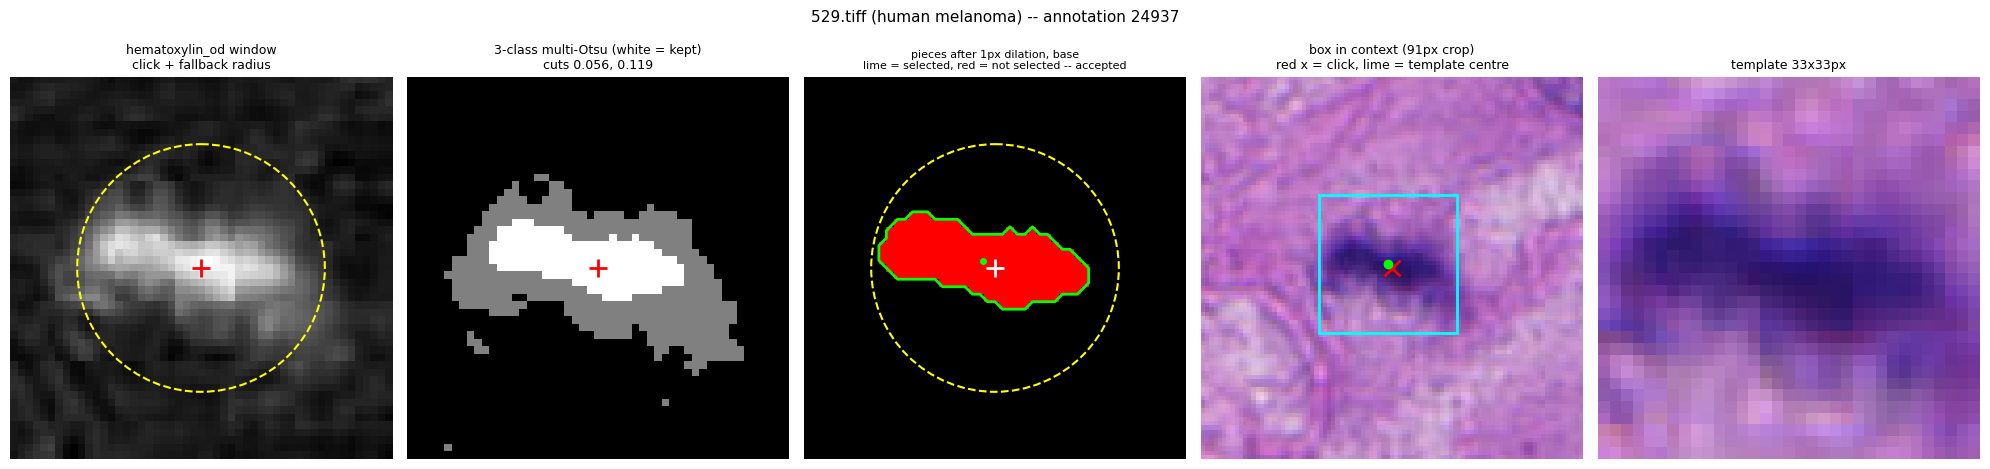

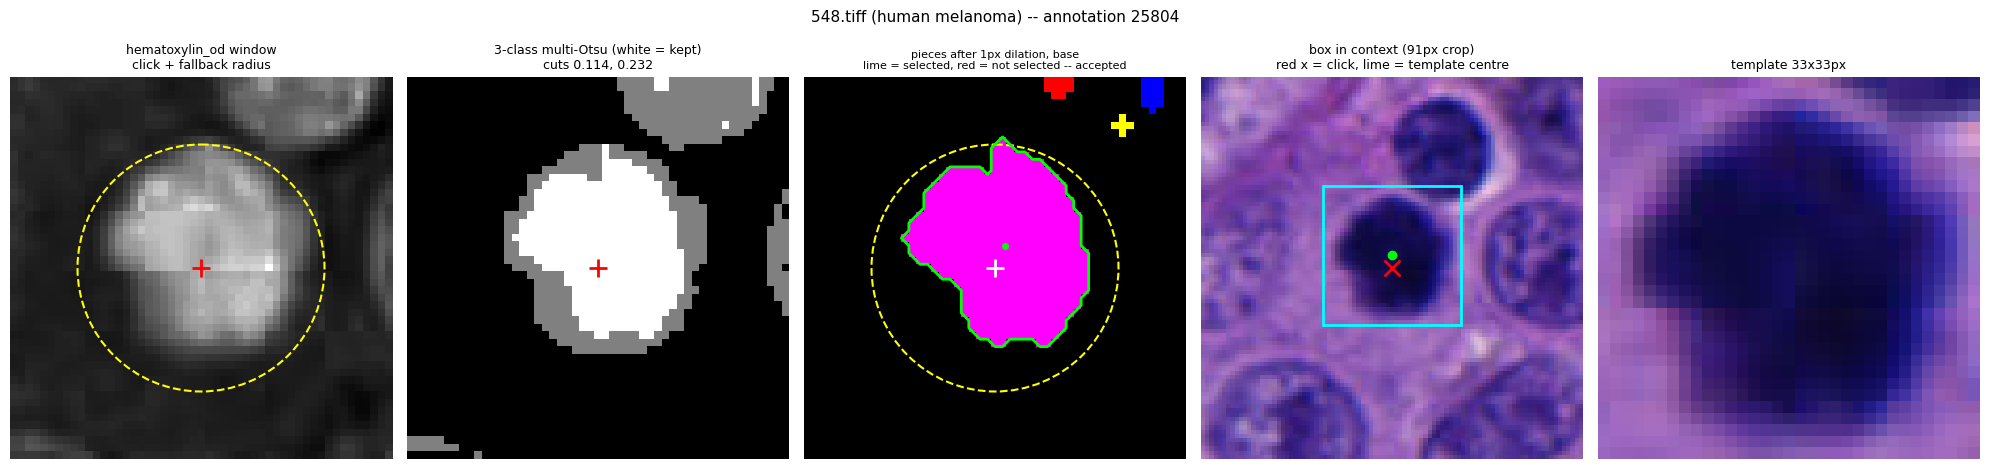

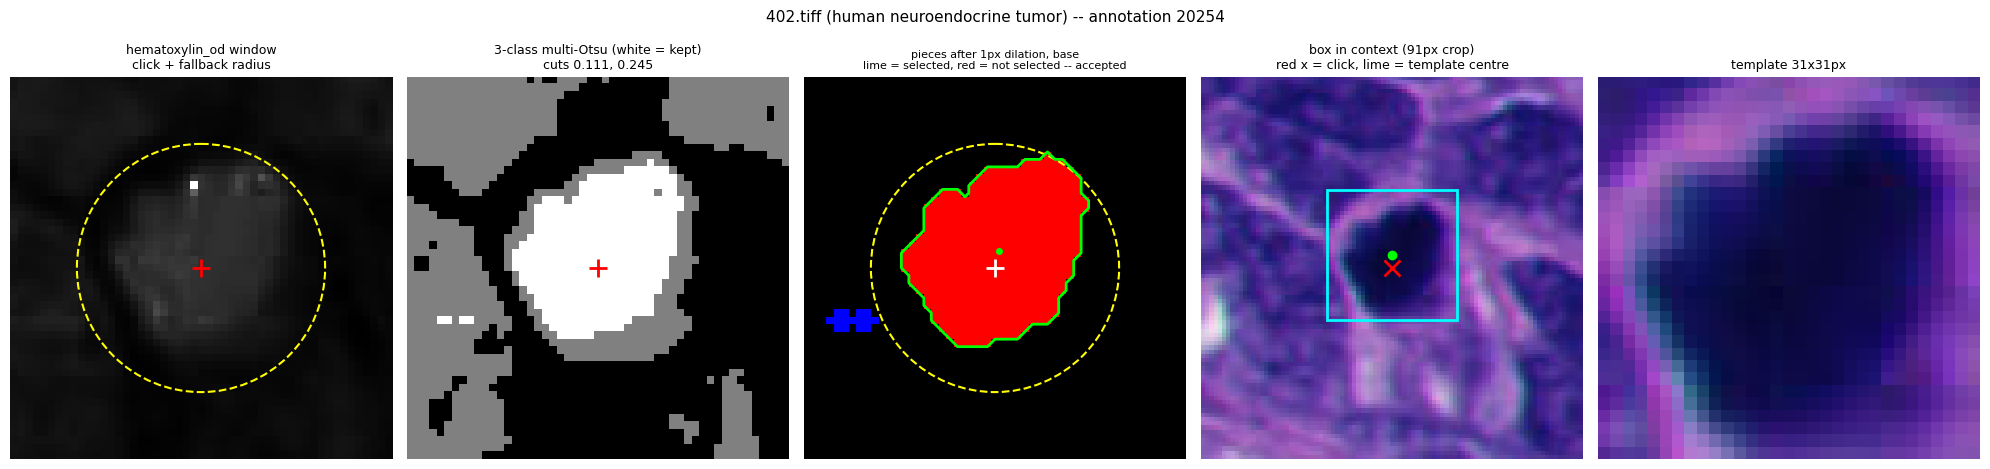

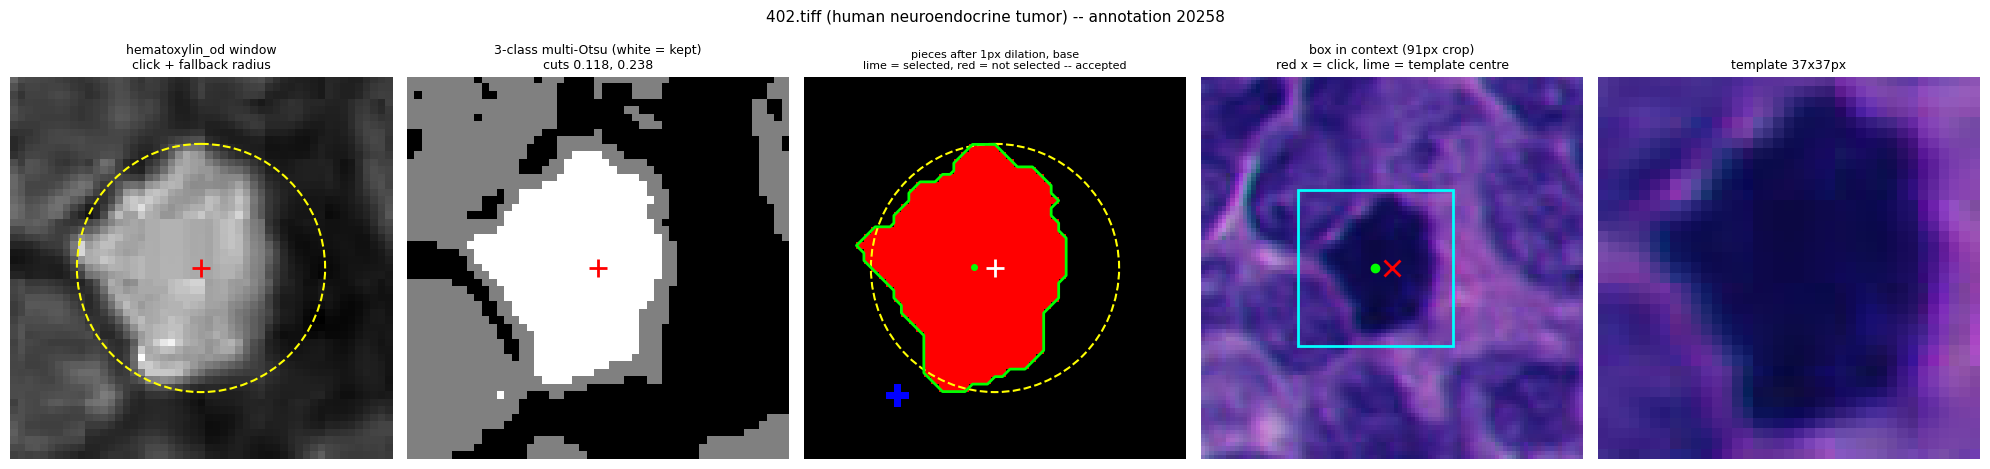

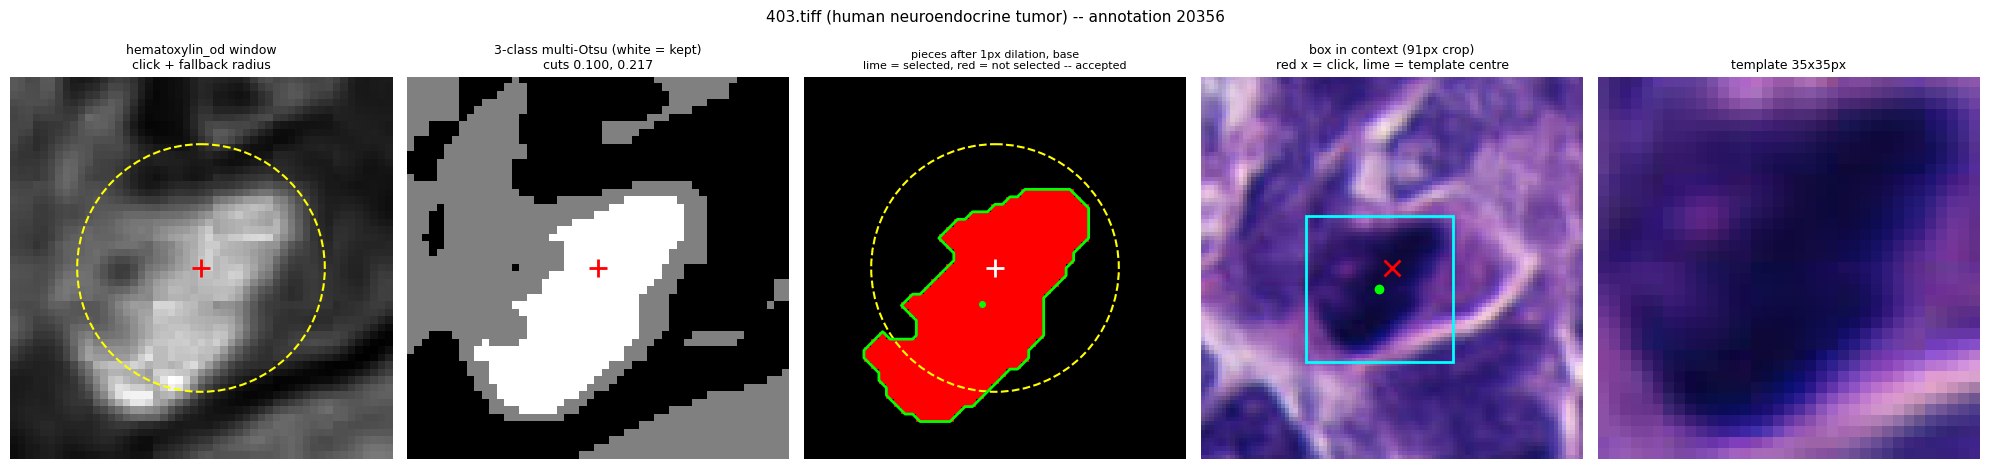

In [7]:
for c in CLICKS:
    fn, ann_id = c['file_name'], c['ann_id']
    fig, axes = plt.subplots(1, 5, figsize=(20, 4.6))
    plot_refinement(axes, RESULTS[(fn, ann_id)], ROIS[fn]['rgb'], c['cx'], c['cy'])
    fig.suptitle(f"{fn} ({c['domain']}) -- annotation {ann_id}", fontsize=11, y=1.03)
    fig.tight_layout()
    fig.savefig(f"{OUT_PREFIX}_{fn.replace('.tiff', '')}_{ann_id}.png", dpi=110, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## Summary table

`offset_px` is the distance from the click to the template centre.

In [8]:
rows = []
for c in CLICKS:
    r, mpp = RESULTS[(c['file_name'], c['ann_id'])], ROIS[c['file_name']]['mpp']
    rows.append(dict(file_name=c['file_name'], ann_id=c['ann_id'], domain=c['domain'], mpp=round(mpp, 4), accepted=r['accepted'], mode=r['mode'],
                     n_pieces=len(r['selected']), selection_um2=None if r['selection_mask'] is None else round(float(r['selection_mask'].sum()) * mpp ** 2, 2),
                     base_size_px=r['base_size'], pad_px=r['pad_px'], base_size_um=None if r['base_size'] is None else round(r['base_size'] * mpp, 2),
                     center_x=None if r['center_xy'] is None else r['center_xy'][0], center_y=None if r['center_xy'] is None else r['center_xy'][1],
                     offset_px=None if r['center_xy'] is None else round(float(np.hypot(r['center_xy'][0] - c['cx'], r['center_xy'][1] - c['cy'])), 1)))
SUMMARY = pd.DataFrame(rows)
SUMMARY.to_csv(f'{OUT_PREFIX}_summary.csv', index=False)
print(f'-> {OUT_PREFIX}_summary.csv')
SUMMARY

-> multiotsurefine14_summary.csv


,file_name,ann_id,domain,mpp,accepted,mode,n_pieces,selection_um2,base_size_px,pad_px,base_size_um,center_x,center_y,offset_px
0,300.tiff,14499,canine cutaneous mast cell tumor,0.2533,True,base,1,16.23,29,2,7.35,1411.5,3555.0,4.0
1,300.tiff,14575,canine cutaneous mast cell tumor,0.2533,True,fallback,2,13.86,33,2,8.36,3418.5,2278.5,4.9
2,300.tiff,14581,canine cutaneous mast cell tumor,0.2533,True,fallback,3,21.62,35,2,8.87,4284.0,2525.5,2.5
3,301.tiff,14969,canine cutaneous mast cell tumor,0.2533,True,base,1,30.16,37,2,9.37,5910.0,3553.5,5.6
4,201.tiff,4457,canine lung cancer,0.2482,True,base,1,21.80,33,2,8.19,4093.0,1978.0,4.0
5,201.tiff,4469,canine lung cancer,0.2482,True,base,1,23.34,33,2,8.19,6263.0,3300.0,2.2
6,233.tiff,5761,canine lung cancer,0.2482,True,base,1,24.82,29,2,7.20,4419.5,2138.5,0.7
7,245.tiff,6243,canine lymphosarcoma,0.2482,True,fallback,2,11.76,33,2,8.19,798.5,169.5,4.5
8,245.tiff,6274,canine lymphosarcoma,0.2482,True,fallback,2,22.73,39,2,9.68,6357.5,536.5,2.1
9,245.tiff,6317,canine lymphosarcoma,0.2482,True,base,1,14.53,25,2,6.20,4768.5,2187.0,6.3
